In [60]:
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, Optional, List, Tuple
from collections import Counter
import re
import json

# 1. Load data

In [2]:
data = pd.read_csv("../data/processed/matches-pre2018.csv")
data

,Year,Stage,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,RoundID,MatchID,Home Team Initials,Away Team Initials
0,1930,Group 1,France,4,1,Mexico,,4444,3,0,201,1096,FRA,MEX
1,1930,Group 4,USA,3,0,Belgium,,18346,2,0,201,1090,USA,BEL
2,1930,Group 2,Yugoslavia,2,1,Brazil,,24059,2,0,201,1093,YUG,BRA
3,1930,Group 3,Romania,3,1,Peru,,2549,1,0,201,1098,ROU,PER
4,1930,Group 1,Argentina,1,0,France,,23409,0,0,201,1085,ARG,FRA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
831,2014,Quarter-finals,Argentina,1,0,Belgium,,68551,1,0,255953,300186504,ARG,BEL
832,2014,Round of 16,Netherlands,2,1,Mexico,,58817,0,0,255951,300186508,NED,MEX
833,2014,Round of 16,Costa Rica,1,1,Greece,Costa Rica win on penalties (5 - 3),41242,0,0,255951,300186459,CRC,GRE
834,2014,Round of 16,Argentina,1,0,Switzerland,Argentina win after extra time,63255,0,0,255951,300186503,ARG,SUI


# 2. Years, final and 3rd place matches

### Years

In [3]:
unique_years = sorted(data["Year"].unique().tolist())
wc_years = set(unique_years)

print(f"Number of unique world cup years: {len(wc_years)}")
print("World cup years:")
for year in wc_years:
    print(f"- {year}")

Number of unique world cup years: 20
World cup years:
- 1930
- 1934
- 1938
- 1950
- 1954
- 1958
- 1962
- 1966
- 1970
- 1974
- 1978
- 1982
- 1986
- 1990
- 1994
- 1998
- 2002
- 2006
- 2010
- 2014


### Final matches

In [5]:
data["Stage"].value_counts()

Stage
Round of 16                 64
Group 1                     62
Quarter-finals              62
Group B                     60
Group A                     60
Group 2                     59
Group 3                     56
Group 4                     55
Group C                     48
Group D                     48
Group F                     48
Group E                     48
Semi-finals                 34
Group H                     30
Group G                     30
Final                       19
Match for third place       15
Group 6                     12
First round                  9
Preliminary round            8
Group 5                      6
Third place                  2
Play-off for third place     1
Name: count, dtype: int64

In [6]:
final_matches = data[data["Stage"] == "Final"]
final_matches

,Year,Stage,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,RoundID,MatchID,Home Team Initials,Away Team Initials
17,1930,Final,Uruguay,4,2,Argentina,,68346,1,2,405,1087,URU,ARG
34,1934,Final,Italy,2,1,Czechoslovakia,Italy win after extra time,55000,0,0,3490,1134,ITA,TCH
52,1938,Final,Italy,4,2,Hungary,,45000,3,1,3487,1174,ITA,HUN
100,1954,Final,Germany FR,3,2,Hungary,,62500,2,2,3484,1278,FRG,HUN
135,1958,Final,Brazil,5,2,Sweden,,49737,2,1,3482,1343,BRA,SWE
167,1962,Final,Brazil,3,1,Czechoslovakia,,68679,1,1,3480,1463,BRA,TCH
199,1966,Final,England,4,2,Germany FR,England win after extra time,96924,0,0,3478,1633,ENG,FRG
231,1970,Final,Brazil,4,1,Italy,,107412,1,1,3476,1765,BRA,ITA
269,1974,Final,Netherlands,1,2,Germany FR,,78200,1,2,605,2063,NED,FRG
307,1978,Final,Argentina,3,1,Netherlands,Argentina win after extra time,71483,0,0,639,2198,ARG,NED


In [7]:
print(f"Number of final matches: {len(final_matches)}")

final_matches_years = set(sorted(final_matches["Year"].values.tolist()))
print(f"Final matches years:")
for year in final_matches_years:
    print(f"- {year}")

Number of final matches: 19
Final matches years:
- 1930
- 1934
- 1938
- 1954
- 1958
- 1962
- 1966
- 1970
- 1974
- 1978
- 1982
- 1986
- 1990
- 1994
- 1998
- 2002
- 2006
- 2010
- 2014


20 world cups, but 19 final matches, one is missing

In [8]:
final_matches_missing = wc_years.difference(final_matches_years)
print("Missing final matches:")
for year in final_matches_missing:
    print(f"- {year}")

Missing final matches:
- 1950


### 3rd place matches

In [9]:
third_place_stages = ["Third place", "Match for third place", "Play-off for third place"]
third_place_matches = data[data["Stage"].isin(third_place_stages)]
third_place_matches

,Year,Stage,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,RoundID,MatchID,Home Team Initials,Away Team Initials
33,1934,Match for third place,Germany,3,2,Austria,,7000,3,1,3491,1105,GER,AUT
51,1938,Match for third place,Brazil,4,2,Sweden,,12000,1,2,3488,1151,BRA,SWE
99,1954,Match for third place,Austria,3,1,Uruguay,,32000,1,1,3485,1239,AUT,URU
134,1958,Match for third place,France,6,3,Germany FR,,32483,3,1,3483,1382,FRA,FRG
166,1962,Match for third place,Chile,1,0,Yugoslavia,,66697,0,0,3481,1475,CHI,YUG
198,1966,Match for third place,Portugal,2,1,Soviet Union,,87696,1,1,3479,1709,POR,URS
230,1970,Match for third place,Germany FR,1,0,Uruguay,,104403,1,0,3477,1843,FRG,URU
268,1974,Match for third place,Brazil,0,1,Poland,,77100,0,0,264,1984,BRA,POL
306,1978,Match for third place,Brazil,2,1,Italy,,69659,0,1,280,2247,BRA,ITA
358,1982,Match for third place,Poland,3,2,France,,28000,2,1,676,921,POL,FRA


In [10]:
print(f"Number of matches for 3rd place: {len(third_place_matches)}")

third_place_years = set(sorted(third_place_matches["Year"].values.tolist()))
print("3rd place matches:")
for year in third_place_years:
    print(f"- {year}")

Number of matches for 3rd place: 18
3rd place matches:
- 2010
- 1954
- 1986
- 1958
- 1990
- 1962
- 1994
- 1934
- 1966
- 1998
- 1938
- 1970
- 2002
- 2014
- 1974
- 2006
- 1978
- 1982


20 world cups, but 18 matches for 3rd place

In [11]:
third_place_missing = wc_years.difference(third_place_years)
print("Missing third place years:")
for year in third_place_missing:
    print(f"- {year}")

Missing third place years:
- 1930
- 1950


# 3. Winners/losers/draw full time

In [27]:
def full_time_outcome(row: pd.Series) -> Dict[str, str]:
    win_lose = {
        "Winner": "",
        "Loser": ""
    }

    home_team = row["Home Team Name"]
    away_team = row["Away Team Name"]
    draw = "Draw"

    home_goals = row["Home Team Goals"]
    away_goals = row["Away Team Goals"]

    if home_goals > away_goals:
        win_lose["Winner"] = home_team
        win_lose["Loser"] = away_team
    elif away_goals > home_goals:
        win_lose["Winner"] = away_team
        win_lose["Loser"] = home_team
    else:
        win_lose["Winner"] = draw
        win_lose["Loser"] = draw

    return win_lose


full_time_outcomes = data.apply(full_time_outcome, axis=1, result_type="expand")
data[["Winner", "Loser"]] = full_time_outcomes

In [28]:
data[["Home Team Name", "Home Team Goals", "Away Team Goals", "Away Team Name", "Winner", "Loser"]]

,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Winner,Loser
0,France,4,1,Mexico,France,Mexico
1,USA,3,0,Belgium,USA,Belgium
2,Yugoslavia,2,1,Brazil,Yugoslavia,Brazil
3,Romania,3,1,Peru,Romania,Peru
4,Argentina,1,0,France,Argentina,France
...,...,...,...,...,...,...
831,Argentina,1,0,Belgium,Argentina,Belgium
832,Netherlands,2,1,Mexico,Netherlands,Mexico
833,Costa Rica,1,1,Greece,Draw,Draw
834,Argentina,1,0,Switzerland,Argentina,Switzerland


In [15]:
def outcomes(data: pd.DataFrame) -> Dict[str, int]:
    home_wins = (data["Winner"] == data["Home Team Name"]).sum()
    away_wins = (data["Winner"] == data["Away Team Name"]).sum()
    draws = (data["Winner"] == "Draw").sum()

    return {
        "Home Team win": home_wins,
        "Draw": draws,
        "Away Team win": away_wins
    }


def draw_outcomes_bar(outcomes: Dict[str, int], title: str):
    plt.figure(figsize=(8, 5))
    bars = plt.bar(outcomes.keys(), outcomes.values())

    plt.title(title)
    plt.xlabel("Outcome")
    plt.ylabel("Matches")

    plt.bar_label(bars, padding=3)

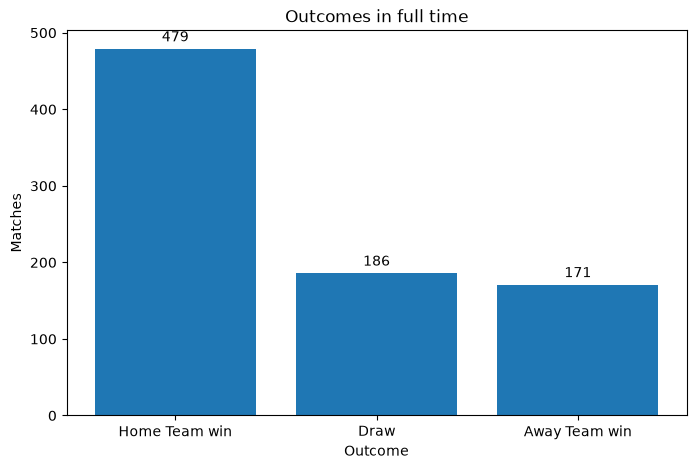

In [16]:
full_time_outcomes = outcomes(data)
draw_outcomes_bar(full_time_outcomes, "Outcomes in full time")

# 4. Win conditions

In [17]:
data["Win conditions"].unique()

<StringArray>
[                                            ' ',
                 'Austria win after extra time ',
                   'Italy win after extra time ',
                  'Brazil win after extra time ',
          'Czechoslovakia win after extra time ',
                 'Hungary win after extra time ',
        'Northern Ireland win after extra time ',
                 'England win after extra time ',
              'Germany FR win after extra time ',
                 'Uruguay win after extra time ',
               'Argentina win after extra time ',
                    ' win on penalties (5 - 4) ',
                 'Belgium win after extra time ',
              'France win on penalties (3 - 4) ',
          'Germany FR win on penalties (4 - 1) ',
             'Belgium win on penalties (4 - 5) ',
                  'France win after extra time ',
                'Cameroon win after extra time ',
 'Republic of Ireland win on penalties (5 - 4) ',
              'Yugoslavia win after 

In [30]:
WINNER_PATERN = re.compile(
    r"^(.+?)\s+win\s+(?:after extra time|on penalties|after Golden Goal)",
    re.IGNORECASE
)
PENALTIES_PATERN = re.compile(
    r"win on penalties\s*\((\d+)\s*-\s*(\d+)\)",
    re.IGNORECASE
)


def pick_winer(home_team: str, away_team: str, home_goals: int, away_goals: int) -> Optional[str]:
    if home_goals > away_goals:
        return home_team
    if away_goals > home_goals:
        return away_team 
    return None
    

def parse_win_condition(row: pd.Series) -> Dict[str, str]:
    result = {
        "Winner": row["Winner"],
        "Loser": row["Loser"]
    }

    condition = str(row["Win conditions"]).strip()
    if not condition:
        return result

    home_team, away_team = row["Home Team Name"], row["Away Team Name"]
    winner_match = WINNER_PATERN.search(condition)
    penalty_match = PENALTIES_PATERN.search(condition)

    if winner_match:
        winner = winner_match.group(1).strip()
    elif penalty_match:
        home_penalties, away_penalties = int(penalty_match.group(1)), int(penalty_match.group(2))
        winner = pick_winer(home_team, away_team, home_penalties, away_penalties)
    else:
        home_goals, away_goals = row["Home Team Goals"], row["Away Team Goals"]
        winner = pick_winer(home_team, away_team, home_goals, away_goals)

    if winner == home_team:
        return {"Winner": home_team, "Loser": away_team}
    if winner == away_team:
        return {"Winner": away_team, "Loser": home_team}

    return result


In [31]:
results = data.apply(parse_win_condition, axis=1, result_type="expand")
data[["Winner", "Loser"]] = results

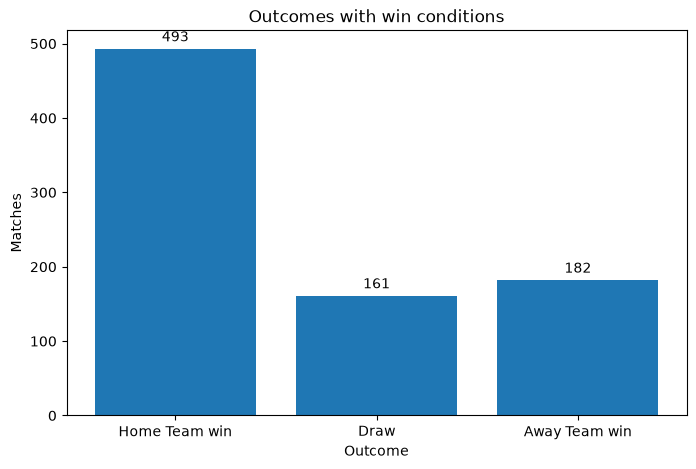

In [32]:
win_cons_outcomes = outcomes(data)
draw_outcomes_bar(win_cons_outcomes, "Outcomes with win conditions")

# 5. Goals

## Half-time goals

In [24]:
data["Half-Time Goals"] = data["Half-time Home Goals"] + data["Half-time Away Goals"]
data[["Half-time Home Goals", "Half-time Away Goals", "Half-Time Goals"]]

,Half-time Home Goals,Half-time Away Goals,Half-Time Goals
0,3,0,3
1,2,0,2
2,2,0,2
3,1,0,1
4,0,0,0
...,...,...,...
831,1,0,1
832,0,0,0
833,0,0,0
834,0,0,0


## Full-time goals

In [25]:
data["Goals"] = data["Home Team Goals"] + data["Away Team Goals"]
data[["Home Team Goals", "Away Team Goals", "Goals"]]

,Home Team Goals,Away Team Goals,Goals
0,4,1,5
1,3,0,3
2,2,1,3
3,3,1,4
4,1,0,1
...,...,...,...
831,1,0,1
832,2,1,3
833,1,1,2
834,1,0,1


# 6. World cup info

## 1st and 2nd place

In [46]:
finals = (
    data.loc[data["Stage"] == "Final", ["Year", "Winner", "Loser"]]
    .rename(columns={"Winner": "1st place", "Loser": "2nd place"})
)
missing_1950 = pd.DataFrame([{"Year": 1950, "1st place": "Uruguay", "2nd place": "Brazil"}])

df_first_second = pd.concat([finals, missing_1950], ignore_index=True)
df_first_second = df_first_second.sort_values("Year", ignore_index=True)
df_first_second

,Year,1st place,2nd place
0,1930,Uruguay,Argentina
1,1934,Italy,Czechoslovakia
2,1938,Italy,Hungary
3,1950,Uruguay,Brazil
4,1954,Germany FR,Hungary
5,1958,Brazil,Sweden
6,1962,Brazil,Czechoslovakia
7,1966,England,Germany FR
8,1970,Brazil,Italy
9,1974,Germany FR,Netherlands


## 3rd and 4th place

In [49]:
third_place = (
    data.loc[data["Stage"].isin(third_place_stages), ["Year", "Winner", "Loser"]]
    .rename(columns={"Winner": "3rd place", "Loser": "4th place"})
)

missing = [
    {"Year": 1930, "3rd place": "Yugoslavia", "4th place": "USA"},
    {"Year": 1950, "3rd place": "Sweden", "4th place": "Spain"},
]
df_missing = pd.DataFrame(missing)
df_missing

df_third_fourth = pd.concat([third_place, df_missing], ignore_index=True)
df_third_fourth = df_third_fourth.sort_values("Year", ignore_index=True)
df_third_fourth

,Year,3rd place,4th place
0,1930,Yugoslavia,USA
1,1934,Germany,Austria
2,1938,Brazil,Sweden
3,1950,Sweden,Spain
4,1954,Austria,Uruguay
5,1958,France,Germany FR
6,1962,Chile,Yugoslavia
7,1966,Portugal,Soviet Union
8,1970,Germany FR,Uruguay
9,1974,Poland,Brazil


## Games

In [40]:
df_games = data.groupby("Year").size().reset_index(name="Games")
df_games

,Year,Games
0,1930,18
1,1934,17
2,1938,18
3,1950,22
4,1954,26
5,1958,35
6,1962,32
7,1966,32
8,1970,32
9,1974,38


## Goals

In [41]:
df_goals = data.groupby("Year")[["Half-Time Goals", "Goals"]].sum().reset_index()
df_goals


,Year,Half-Time Goals,Goals
0,1930,32,70
1,1934,29,70
2,1938,30,84
3,1950,41,88
4,1954,59,140
5,1958,54,126
6,1962,39,89
7,1966,40,89
8,1970,32,95
9,1974,45,97


## Average goals per game

In [42]:
avg_half_time = df_goals["Half-Time Goals"] / df_games["Games"]
avg_goals = df_goals["Goals"] / df_games["Games"]

df_goals["Average Goals Half-time"] = round(avg_half_time, 2)
df_goals["Average Goals"] = round(avg_goals, 2)
df_goals

,Year,Half-Time Goals,Goals,Average Goals Half-time,Average Goals
0,1930,32,70,1.78,3.89
1,1934,29,70,1.71,4.12
2,1938,30,84,1.67,4.67
3,1950,41,88,1.86,4.00
4,1954,59,140,2.27,5.38
5,1958,54,126,1.54,3.60
6,1962,39,89,1.22,2.78
7,1966,40,89,1.25,2.78
8,1970,32,95,1.00,2.97
9,1974,45,97,1.18,2.55


## Attendance

In [43]:
df_attendance = data.groupby("Year")[["Attendance"]].sum().reset_index()
df_attendance

,Year,Attendance
0,1930,590549
1,1934,363000
2,1938,375700
3,1950,1045246
4,1954,768607
5,1958,819810
6,1962,893172
7,1966,1563135
8,1970,1603975
9,1974,1865753


## Average attendance

In [44]:
avg_attendance = df_attendance["Attendance"] / df_games["Games"]
df_attendance["Average Attendance"] = round(avg_attendance, 2)
df_attendance

,Year,Attendance,Average Attendance
0,1930,590549,32808.28
1,1934,363000,21352.94
2,1938,375700,20872.22
3,1950,1045246,47511.18
4,1954,768607,29561.81
5,1958,819810,23423.14
6,1962,893172,27911.62
7,1966,1563135,48847.97
8,1970,1603975,50124.22
9,1974,1865753,49098.76


## Teams

### IR Iran and Iran same team different name

In [50]:
data.loc[data["Home Team Name"] == "IR Iran", "Home Team Name"] = "Iran"
data.loc[data["Away Team Name"] == "IR Iran", "Away Team Name"] = "Iran"

In [51]:
df_teams = (data.melt(
            id_vars="Year",
            value_vars=["Home Team Name", "Away Team Name"],
            value_name="Team",
        )
        .groupby("Year")["Team"]
        .nunique()
        .reset_index(name="Teams")
)
df_teams

,Year,Teams
0,1930,13
1,1934,16
2,1938,15
3,1950,13
4,1954,16
5,1958,16
6,1962,16
7,1966,16
8,1970,16
9,1974,16


## Most Scoring Team

In [52]:
home_goals = data[["Year", "Home Team Name", "Home Team Goals"]].rename(
    columns={
        "Home Team Name": "Team",
        "Home Team Goals": "Goals"
    }
)

away_goals = data[["Year", "Away Team Name", "Away Team Goals"]].rename(
    columns={
        "Away Team Name": "Team",
        "Away Team Goals": "Goals"
    }
)

team_goals = pd.concat([home_goals, away_goals])
team_goals = (
    team_goals.groupby(["Year", "Team"])["Goals"]
    .sum()
    .reset_index()
)

most_scoring_df = team_goals.loc[
    team_goals.groupby("Year")["Goals"].idxmax()
].rename(columns={
    "Team": "Most Scoring Team",
    "Goals": "Most Scoring Goals"
})
most_scoring_df

,Year,Most Scoring Team,Most Scoring Goals
0,1930,Argentina,18
22,1934,Italy,12
36,1938,Hungary,15
45,1950,Brazil,22
64,1954,Hungary,27
78,1958,France,23
90,1962,Brazil,14
116,1966,Portugal,17
122,1970,Brazil,19
147,1974,Poland,16


## Games with extra time and penalties

In [53]:
penalties = data["Win conditions"].str.contains(r"win on penalties", case=False)
extra_time = penalties | data["Win conditions"].str.contains(r"after extra time|after golden goal", case=False)

df_extra_penalties = (
    data.assign(ExtraTime=extra_time, Penalties=penalties)
    .groupby("Year", as_index=False)[["ExtraTime", "Penalties"]]
    .sum()
)
df_extra_penalties

,Year,ExtraTime,Penalties
0,1930,0,0
1,1934,2,0
2,1938,3,0
3,1950,0,0
4,1954,1,0
5,1958,1,0
6,1962,0,0
7,1966,1,0
8,1970,3,0
9,1974,0,0


# 7. Merge

In [55]:
world_cup_df = pd.DataFrame(columns=["Year"])
world_cup_df["Year"] = unique_years
world_cup_df

,Year
0,1930
1,1934
2,1938
3,1950
4,1954
5,1958
6,1962
7,1966
8,1970
9,1974


In [57]:
world_cup_df = (
    df_first_second
    .merge(df_third_fourth, on="Year", how="outer")
    .merge(df_games, on="Year", how="outer")
    .merge(df_extra_penalties, on="Year", how="outer")
    .merge(df_teams, on="Year", how="outer")
    .merge(df_goals, on="Year", how="outer")
    .merge(df_attendance, on="Year", how="outer")
    .merge(most_scoring_df, on="Year", how="outer")
    .sort_values("Year")
    .reset_index(drop=True)
)
world_cup_df = world_cup_df.replace({
    "Germany FR": "Germany",
    "German DR": "Germany"
})
world_cup_df

,Year,1st place,2nd place,3rd place,4th place,Games,ExtraTime,Penalties,Teams,Half-Time Goals,Goals,Average Goals Half-time,Average Goals,Attendance,Average Attendance,Most Scoring Team,Most Scoring Goals
0,1930,Uruguay,Argentina,Yugoslavia,USA,18,0,0,13,32,70,1.78,3.89,590549,32808.28,Argentina,18
1,1934,Italy,Czechoslovakia,Germany,Austria,17,2,0,16,29,70,1.71,4.12,363000,21352.94,Italy,12
2,1938,Italy,Hungary,Brazil,Sweden,18,3,0,15,30,84,1.67,4.67,375700,20872.22,Hungary,15
3,1950,Uruguay,Brazil,Sweden,Spain,22,0,0,13,41,88,1.86,4.00,1045246,47511.18,Brazil,22
4,1954,Germany,Hungary,Austria,Uruguay,26,1,0,16,59,140,2.27,5.38,768607,29561.81,Hungary,27
5,1958,Brazil,Sweden,France,Germany,35,1,0,16,54,126,1.54,3.60,819810,23423.14,France,23
6,1962,Brazil,Czechoslovakia,Chile,Yugoslavia,32,0,0,16,39,89,1.22,2.78,893172,27911.62,Brazil,14
7,1966,England,Germany,Portugal,Soviet Union,32,1,0,16,40,89,1.25,2.78,1563135,48847.97,Portugal,17
8,1970,Brazil,Italy,Germany,Uruguay,32,3,0,16,32,95,1.00,2.97,1603975,50124.22,Brazil,19
9,1974,Germany,Netherlands,Poland,Brazil,38,0,0,16,45,97,1.18,2.55,1865753,49098.76,Poland,16


# 7. 2018, 2022, 2026 World cups

In [58]:
def read_json(filename: str) -> Dict:
    with open(filename, "r", encoding="utf-8") as file:
        return json.load(file)


file2018 = "../data/raw/matches-2018.json"
file2022 = "../data/raw/matches-2022.json"
file2026 = "../data/raw/matches-2026.json"
tournaments = [read_json(file2018), read_json(file2022), read_json(file2026)]

In [71]:
def goal_minute(goal: Dict) -> Optional[int]:
    try:
        return int(str(goal.get("minute", "")).split("+")[0])
    except ValueError:
        return None 


def count_goals(goals: Optional[List[Dict]], max_minute: Optional[int]=None) -> int:
    count = 0

    for goal in goals or []:
        minute = goal_minute(goal)

        if not minute:
            continue
        if max_minute and minute > max_minute:
            continue

        count += 1

    return count


def went_to_penalties(match: Dict) -> bool:
    score = match.get("score")
    return isinstance(score, dict) and bool(score.get("p"))


def went_to_extra_time(match: Dict) -> bool:
    score = match.get("score")

    if isinstance(score, dict) and (score.get("et") or score.get("p")):
        return True

    all_goals = (match.get("goals1") or []) + (match.get("goals2") or [])
    minutes = [goal_minute(goal) for goal in all_goals]

    return any(minute and minute > 90 for minute in minutes)


def get_final_result(match: dict) -> Tuple[int, int]:
    score = match.get("score")

    if isinstance(score, dict):
        for k in ("p", "et", "ft"):
            if score.get(k):
                return tuple(score[k])
    elif score:
        return tuple(score)

    return count_goals(match.get("goals1")), count_goals(match.get("goals2"))


def winner_loser(match: Dict) -> Tuple[Optional[str], Optional[str]]:
    goals1, goals2 = get_final_result(match)

    if goals1 > goals2:
        return match["team1"], match["team2"]
    if goals2 > goals1:
        return match["team2"], match["team1"]

    return None, None


def extract_world_cup_stats(tournament: Dict) -> Dict:
    matches = tournament["matches"]
    year = int(matches[0]["date"][:4])

    teams = set()
    team_goals = Counter()

    goals = half_time_goals = attendance = extra_time = penalties = 0
    first = second = third = fourth = None 

    for match in matches:
        team1, team2 = match["team1"], match["team2"]
        goals1, goals2 = match.get("goals1"), match.get("goals2")

        teams.update([team1, team2])
        team_goals[team1] += count_goals(goals1)
        team_goals[team2] += count_goals(goals2)

        goals += count_goals(goals1) + count_goals(goals2)
        half_time_goals += count_goals(goals1, 45) + count_goals(goals2, 45)
        attendance += int(match.get("attendance") or 0)

        extra_time += went_to_extra_time(match)
        penalties += went_to_penalties(match)

        round_name = match["round"].lower()
        if "final" in round_name:
            first, second = winner_loser(match)
        elif "third" in round_name:
            third, fourth = winner_loser(match)

    games = len(matches)
    most_scoring_team, most_scoring_goals = team_goals.most_common(1)[0]

    return {
        "Year": year,
        "1st place": first,
        "2nd place": second,
        "3rd place": third,
        "4th place": fourth,
        "Games": games,
        "ExtraTime": extra_time,
        "Penalties": penalties,
        "Teams": len(teams),
        "Half-Time Goals": half_time_goals,
        "Goals": goals,
        "Average Goals Half-time": round(half_time_goals / games, 2),
        "Average Goals": round(goals / games, 2),
        "Attendance": attendance,
        "Average Attendance": round(attendance / games, 2),
        "Most Scoring Team": most_scoring_team,
        "Most Scoring Goals": most_scoring_goals,
    }


In [72]:
modern_world_cups = pd.DataFrame([
    extract_world_cup_stats(tournament)
    for tournament in tournaments
])

modern_world_cups

,Year,1st place,2nd place,3rd place,4th place,Games,ExtraTime,Penalties,Teams,Half-Time Goals,Goals,Average Goals Half-time,Average Goals,Attendance,Average Attendance,Most Scoring Team,Most Scoring Goals
0,2018,France,Croatia,Belgium,England,64,5,4,32,65,169,1.02,2.64,3031768,47371.38,Belgium,16
1,2022,Argentina,France,Croatia,Morocco,64,5,5,32,67,172,1.05,2.69,3404252,53191.44,France,16
2,2026,Spain,Argentina,England,France,104,9,4,48,126,308,1.21,2.96,6810966,65490.06,France,20


In [75]:
world_cup_df = (
    world_cup_df
    .set_index("Year")
    .combine_first(modern_world_cups.set_index("Year"))
    .reset_index()
    .sort_values("Year")
    .reset_index(drop=True)
)
world_cup_df

,Year,1st place,2nd place,3rd place,4th place,Games,ExtraTime,Penalties,Teams,Half-Time Goals,Goals,Average Goals Half-time,Average Goals,Attendance,Average Attendance,Most Scoring Team,Most Scoring Goals
0,1930,Uruguay,Argentina,Yugoslavia,USA,18,0,0,13,32,70,1.78,3.89,590549,32808.28,Argentina,18
1,1934,Italy,Czechoslovakia,Germany,Austria,17,2,0,16,29,70,1.71,4.12,363000,21352.94,Italy,12
2,1938,Italy,Hungary,Brazil,Sweden,18,3,0,15,30,84,1.67,4.67,375700,20872.22,Hungary,15
3,1950,Uruguay,Brazil,Sweden,Spain,22,0,0,13,41,88,1.86,4.00,1045246,47511.18,Brazil,22
4,1954,Germany,Hungary,Austria,Uruguay,26,1,0,16,59,140,2.27,5.38,768607,29561.81,Hungary,27
5,1958,Brazil,Sweden,France,Germany,35,1,0,16,54,126,1.54,3.60,819810,23423.14,France,23
6,1962,Brazil,Czechoslovakia,Chile,Yugoslavia,32,0,0,16,39,89,1.22,2.78,893172,27911.62,Brazil,14
7,1966,England,Germany,Portugal,Soviet Union,32,1,0,16,40,89,1.25,2.78,1563135,48847.97,Portugal,17
8,1970,Brazil,Italy,Germany,Uruguay,32,3,0,16,32,95,1.00,2.97,1603975,50124.22,Brazil,19
9,1974,Germany,Netherlands,Poland,Brazil,38,0,0,16,45,97,1.18,2.55,1865753,49098.76,Poland,16


# 8. Export

In [76]:
world_cup_df.to_csv("../data/processed/world_cups.csv", index=False)